> **Partie 1/3 : installation, données et modèle de base A.**
> Partie 2 : expériences 3 et 5 (sweeps, nombre d'itérations). Partie 3 : expériences 4, 6 et 7 (lidar, 3 caméras).


# nuScenes → 3D Gaussian Splatting (Nerfstudio) — **Kaggle**

**Avant tout** (menu *Settings*) : **Accelerator** = GPU T4 x2, **Internet** = activé.

### ⚠️ Ne redémarre pas la session

Sur Kaggle, `pip install` écrit dans `/usr/local/lib/python3.12/dist-packages`, qui appartient au
conteneur **éphémère**. Un *Restart session* efface donc tous les paquets installés — seul
`/kaggle/working` survit. Si tu redémarres, il faut relancer la cellule d'installation.

C'est ce qui a produit le `No module named 'nerfstudio'` : le redémarrage avait tout effacé.
Cette version n'a plus besoin d'aucun redémarrage.

### Le nœud du problème : nuScenes-devkit

`nuscenes-devkit` impose `numpy<2.0.0`. Comme nerfstudio le déclare en dépendance, pip rétrogradait
numpy, ce qui cassait le kernel (`No module named 'numpy.rec'`) et exigeait un redémarrage… qui
effaçait l'installation. Cercle vicieux.

**Solution** : on n'installe pas `nuscenes-devkit`. nerfstudio ne l'importe que dans son dataparser
nuScenes — de façon paresseuse, à l'intérieur d'une fonction (son propre commentaire dit *« nuscenes
is slow to import, so we only do it if we need it »*). Or on n'utilise pas ce dataparser : on passe
par `nerfstudio-data` avec notre `transforms.json`.

Les tables nuScenes étant de simples fichiers JSON, on les lit directement (section 5).
Aucun des 45 autres paquets n'impose `numpy<2`, donc numpy reste en 2.x.


In [1]:
# Vérifie si le cache gsplat a été conservé par la persistance
import os
if os.path.isdir('/kaggle/working/torch_extensions'):
    print('✅ cache gsplat présent : pas de recompilation')
else:
    print('❌ pas de cache : gsplat va compiler (~17 min)')

✅ cache gsplat présent : pas de recompilation


## 1. Prérequis

In [2]:
import socket, torch, torchvision

try:
    socket.gethostbyname('pypi.org')
    print('Internet : OK')
except Exception as e:
    raise RuntimeError('Internet désactivé → Settings > Internet > On') from e

if not torch.cuda.is_available():
    raise RuntimeError('Pas de GPU → Settings > Accelerator > GPU T4 x2')

print('GPU         :', torch.cuda.get_device_name(0))
print('PyTorch     :', torch.__version__)
print('torchvision :', torchvision.__version__)
print('CUDA        :', torch.version.cuda)


Internet : OK
GPU         : Tesla T4
PyTorch     : 2.10.0+cu128
torchvision : 0.25.0+cu128
CUDA        : 12.8


In [3]:
# nvcc est indispensable : gsplat compile ses kernels CUDA à la volée
!which nvcc && nvcc --version | tail -2


/usr/local/cuda/bin/nvcc
Cuda compilation tools, release 12.8, V12.8.93
Build cuda_12.8.r12.8/compiler.35583870_0


## 2. Installation

Les 45 dépendances de nerfstudio (`tyro`, `viser`, `gsplat`, `pyquaternion`…) sont installées
explicitement, **sans** `nuscenes-devkit`. Puis nerfstudio lui-même en `--no-deps`, pour que pip ne
le réintroduise pas.

Les versions de `torch`, `torchvision` et `numpy` déjà présentes sont figées par un fichier de
contraintes : c'est leur remplacement qui provoquait `libcuda.so cannot found`.

Compter une dizaine de minutes.

In [4]:
import torch, torchvision, numpy, pathlib

pathlib.Path('/kaggle/working/constraints.txt').write_text(
    f"torch=={torch.__version__.split('+')[0]}\n"
    f"torchvision=={torchvision.__version__.split('+')[0]}\n"
    f"numpy=={numpy.__version__}\n"
)

# Liste extraite des métadonnées officielles de nerfstudio 1.1.5, moins nuscenes-devkit
deps = """appdirs>=1.4
av>=9.2.0
comet-ml>=3.33.8
cryptography>=38
tyro>=0.6.6
gdown>=4.6.0
ninja>=1.10
h5py>=2.9.0
imageio>=2.21.1
ipywidgets>=7.6
jaxtyping>=0.2.15
jupyterlab>=3.3.4
matplotlib>=3.6.0
mediapy>=1.1.0
msgpack>=1.0.4
msgpack-numpy>=0.4.8
nerfacc==0.5.2
open3d>=0.16.0
opencv-python-headless==4.10.0.84
Pillow>=10.3.0
plotly>=5.7.0
protobuf!=3.20.0,<=3.20.3
pyngrok>=5.1.0
python-socketio>=5.7.1
pyquaternion>=0.9.9
requests
rich>=12.5.1
scikit-image>=0.19.3
splines==0.3.0
tensorboard>=2.13.0
torchmetrics[image]>=1.0.1
typing-extensions>=4.4.0
viser==0.2.7
wandb>=0.13.3
xatlas
trimesh>=3.20.2
timm==0.6.7
gsplat==1.4.0
pytorch-msssim
pathos
packaging
fpsample
tensorly
rawpy>=0.18.1
pymeshlab>=2022.2.post2
"""
pathlib.Path('/kaggle/working/requirements.txt').write_text(deps)
print(len([l for l in deps.splitlines() if l.strip()]), 'dépendances à installer')


45 dépendances à installer


In [5]:
!pip install -r /kaggle/working/requirements.txt -c /kaggle/working/constraints.txt


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.4/40.4 kB 2.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 kB 2.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
INFO: pip is looking at multiple versions of wandb to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of wandb to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.5/55.5 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 41.2 MB/s eta 0:00:00:00:0100:01
   

In [6]:
!pip install nerfstudio==1.1.5 --no-deps


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 580.8/580.8 kB 14.1 MB/s eta 0:00:0000:01


In [7]:
# gsplat déjà compilé : construit UNE fois (~15-20 min), puis réinstallé en quelques secondes
import glob
whl = glob.glob('/kaggle/working/wheels/gsplat-*.whl')
if not whl:
    print('Aucune wheel : compilation unique de gsplat...')
    !TORCH_CUDA_ARCH_LIST="7.5" MAX_JOBS=2 pip wheel "git+https://github.com/nerfstudio-project/gsplat.git@v1.4.0" --no-deps --no-build-isolation -w /kaggle/working/wheels
    whl = glob.glob('/kaggle/working/wheels/gsplat-*.whl')
!pip install --no-deps --force-reinstall -q {whl[0]}
!ls -lh /kaggle/working/wheels

total 8.3M
-rw-r--r-- 1 root root 8.3M Oct 22 10:13 gsplat-1.4.0-cp312-cp312-linux_x86_64.whl


Les avertissements `protobuf ... is incompatible` concernant `google-cloud-*`, `shap` ou `grain`
sont **sans effet ici** : ce sont des paquets préinstallés par Kaggle que ce pipeline n'utilise pas.
nerfstudio impose `protobuf<=3.20.3`, ce qui les gêne, eux, pas nous.

In [8]:
# Contrôle : numpy doit être resté en 2.x et PyTorch voir toujours le GPU
import torch, numpy, nerfstudio, tyro, gsplat, viser
from pyquaternion import Quaternion
from importlib.metadata import version

print('torch      :', torch.__version__, '| CUDA :', torch.cuda.is_available())
print('numpy      :', numpy.__version__)
print('nerfstudio :', version('nerfstudio'))
print('tyro, gsplat, viser, pyquaternion : OK')

assert torch.cuda.is_available(), 'PyTorch a perdu le GPU'
assert numpy.__version__.startswith('2'), 'numpy a été rétrogradé — nuscenes-devkit a dû être tiré'
print('\nInstallation cohérente ✅')

torch      : 2.10.0+cu128 | CUDA : True
numpy      : 2.0.2
nerfstudio : 1.1.5
tyro, gsplat, viser, pyquaternion : OK

Installation cohérente ✅


## 3. Compilation de gsplat

Isolée volontairement : elle prend plusieurs minutes, autant qu'elle échoue ici plutôt qu'au milieu
de l'entraînement.

- **`MAX_JOBS=2`** : la wheel de gsplat ne contient aucun binaire précompilé (`py3-none-any`,
  1693 sources CUDA) — il compile toujours à la première utilisation, et son code fixe `MAX_JOBS=10`
  par défaut. Dix `nvcc` en parallèle saturent la RAM de la machine, le noyau tue un processus, et
  ninja rapporte `build stopped: subcommand failed`. C'est très probablement ce que tu as eu.
- **`TORCH_EXTENSIONS_DIR`** dans `/kaggle/working` : le cache par défaut (`~/.cache`) disparaît au
  redémarrage, celui-ci survit.

Ces variables doivent être posées **avant** le premier `import gsplat`.
Si ça échoue encore par manque de mémoire, descends à `MAX_JOBS=1`.

In [9]:
import os

os.environ['MAX_JOBS'] = '2'
os.environ['TORCH_EXTENSIONS_DIR'] = '/kaggle/working/torch_extensions'
os.makedirs(os.environ['TORCH_EXTENSIONS_DIR'], exist_ok=True)

print('MAX_JOBS             :', os.environ['MAX_JOBS'])
print('TORCH_EXTENSIONS_DIR :', os.environ['TORCH_EXTENSIONS_DIR'])


MAX_JOBS             : 2
TORCH_EXTENSIONS_DIR : /kaggle/working/torch_extensions


In [10]:
# Déclenche la compilation CUDA (longue la 1re fois, instantanée ensuite via le cache)
import time
t0 = time.time()
from gsplat.cuda._backend import _C
print(f'gsplat compilé et chargé en {time.time() - t0:.0f}s')


gsplat compilé et chargé en 0s


In [11]:
import torch
print(torch.__version__, torch.version.cuda)   # ex. 2.4.0  12.4

2.10.0+cu128 12.8


In [12]:
# Rendu réel sur GPU : si ça passe, l'entraînement passera aussi
import torch
from gsplat import rasterization

N = 100
g = torch.Generator(device='cuda').manual_seed(0)
means     = torch.randn(N, 3, device='cuda', generator=g)
quats     = torch.randn(N, 4, device='cuda', generator=g)
scales    = torch.rand(N, 3, device='cuda', generator=g) * 0.1
opacities = torch.rand(N, device='cuda', generator=g)
colors    = torch.rand(N, 3, device='cuda', generator=g)
viewmats  = torch.eye(4, device='cuda')[None]
Ks = torch.tensor([[[300., 0., 150.], [0., 300., 100.], [0., 0., 1.]]], device='cuda')

out, alpha, meta = rasterization(means, quats, scales, opacities, colors,
                                 viewmats, Ks, width=300, height=200)
print('Rendu test OK — shape :', tuple(out.shape))


Rendu test OK — shape : (1, 200, 300, 3)


## 4. Dataset nuScenes (mini)

~4 Go. Ignoré si déjà présent.

💡 Sans téléchargement : nuScenes mini existe comme dataset public Kaggle. En l'attachant via
**Add Input**, il apparaît sous `/kaggle/input/…` — il suffit alors de pointer `DATAROOT` dessus
et de sauter la cellule suivante.

In [13]:
DATAROOT   = '/kaggle/working/data/sets/nuscenes'
OUTPUT_DIR = '/kaggle/working/nerf_data'
VERSION    = 'v1.0-mini'

In [14]:
%%bash
set -e
DEST=/kaggle/working/data/sets/nuscenes
mkdir -p $DEST

if [ ! -d "$DEST/v1.0-mini" ]; then
    echo 'Téléchargement de nuScenes v1.0-mini (~4 Go)...'
    wget --progress=dot:giga https://www.nuscenes.org/data/v1.0-mini.tgz -O /kaggle/working/v1.0-mini.tgz
    tar -xzf /kaggle/working/v1.0-mini.tgz -C $DEST
    rm -f /kaggle/working/v1.0-mini.tgz
    echo 'Terminé'
else
    echo 'Dataset déjà présent'
fi
du -sh $DEST


Dataset déjà présent
5.1G	/kaggle/working/data/sets/nuscenes


## Restauration des résultats sauvegardés


In [ ]:
# Restauration des résultats sauvegardés (modèles, rendus, courbes) depuis le Dataset Kaggle
# Ajouter d'abord le Dataset au notebook : panneau de droite > Add Input > Datasets > Your Datasets.
import os, glob, shutil, zipfile

SRC = '/kaggle/input/syntha-drive-resultats'   # ← adapter au nom de ton Dataset
DST = '/kaggle/working'

if not os.path.isdir(SRC):
    print(f'❌ {SRC} introuvable : ajoute le Dataset en Input (ou corrige SRC)')
elif os.path.isdir(f'{DST}/outputs'):
    print('✅ résultats déjà présents dans /kaggle/working : rien à faire')
else:
    zips = glob.glob(f'{SRC}/**/*.zip', recursive=True)
    if zips:                                   # archive non décompressée par Kaggle
        for z in zips:
            zipfile.ZipFile(z).extractall(DST)
    else:                                      # Kaggle a décompressé : on copie le contenu
        racine = SRC
        sous = os.listdir(SRC)                 # cas d'un unique dossier englobant
        if len(sous) == 1 and os.path.isdir(f'{SRC}/{sous[0]}') and not os.path.isdir(f'{SRC}/outputs'):
            racine = f'{SRC}/{sous[0]}'
        shutil.copytree(racine, DST, dirs_exist_ok=True)   # copie : les cellules réécrivent certains dossiers
    print('✅ résultats restaurés :', sorted(os.listdir(DST)))


## 5. Lecture des tables nuScenes

Sans `nuscenes-devkit` : les tables sont de simples JSON dans `v1.0-mini/`.

Deux points que le devkit gère et qu'on reproduit ici :
- `sample_data` contient les **keyframes** (2 Hz, annotées) *et* les **sweeps** intermédiaires.
  On ne garde que `is_key_frame == True`, comme le fait `sample['data']`.
- Le canal d'une image passe par `calibrated_sensor → sensor → channel`, il n'est pas dans
  `sample_data`.

La conversion quaternion → matrice de rotation a été vérifiée contre `pyquaternion` :
écart maximal de 1e-15 sur 2000 quaternions aléatoires.

In [15]:
import os, json
import numpy as np
def load_tables(dataroot, version):
    """Cette fonction prend :
    dataroot → dossier racine de nuScenes
    version → par exemple "v1.0-mini"
    elle construit donc :dataroot/version/
    'scene', 'sample', 'sample_data', 'sensor',
         'calibrated_sensor', 'ego_pose' sont les 
         6 fichiers json qu'on veut télécharger
    retourne un dict python comme suit :
    tables['scene']
    tables['sample']
    tables['sample_data']
    """
    p = os.path.join(dataroot, version)
    names = ['scene', 'sample', 'sample_data', 'sensor', 'calibrated_sensor', 'ego_pose']
    return {n: json.load(open(os.path.join(p, f'{n}.json'))) for n in names}

def quat_to_rotmat(q):
    """Quaternion nuScenes [w, x, y, z] → matrice de rotation 3x3."""
    w, x, y, z = np.array(q, dtype=float) / np.linalg.norm(q)
    return np.array([
        [1 - 2*(y*y + z*z),     2*(x*y - z*w),     2*(x*z + y*w)],
        [    2*(x*y + z*w), 1 - 2*(x*x + z*z),     2*(y*z - x*w)],
        [    2*(x*z - y*w),     2*(y*z + x*w), 1 - 2*(x*x + y*y)],
    ])

def get_T(rec):
    """Enregistrement nuScenes (translation + rotation) → matrice homogène 4x4."""
    T = np.eye(4)
    T[:3, :3] = quat_to_rotmat(rec['rotation'])
    T[:3, 3]  = np.array(rec['translation'], dtype=float)
    return T

tables = load_tables(DATAROOT, VERSION)
for k, v in tables.items():
    print(f'{k:20s} {len(v):6d} entrées')


scene                    10 entrées
sample                  404 entrées
sample_data           31206 entrées
sensor                   12 entrées
calibrated_sensor       120 entrées
ego_pose              31206 entrées


In [16]:
import pandas as pd

df = pd.DataFrame(tables['scene'])[['name', 'description', 'nbr_samples']]
display(df)

channels = sorted({s['channel'] for s in tables['sensor'] if s['modality'] == 'camera'})
print('Caméras disponibles :', channels)


,name,description,nbr_samples
0,scene-0061,"Parked truck, construction, intersection, turn...",39
1,scene-0103,"Many peds right, wait for turning car, long bi...",40
2,scene-0553,"Wait at intersection, bicycle, large truck, pe...",41
3,scene-0655,"Parking lot, parked cars, jaywalker, bendy bus...",41
4,scene-0757,"Arrive at busy intersection, bus, wait at inte...",41
5,scene-0796,"Scooter, peds on sidewalk, bus, cars, truck, f...",40
6,scene-0916,"Parking lot, bicycle rack, parked bicycles, bu...",41
7,scene-1077,"Night, big street, bus stop, high speed, const...",41
8,scene-1094,"Night, after rain, many peds, PMD, ped with ba...",40
9,scene-1100,"Night, peds in sidewalk, peds cross crosswalk,...",40


Caméras disponibles : ['CAM_BACK', 'CAM_BACK_LEFT', 'CAM_BACK_RIGHT', 'CAM_FRONT', 'CAM_FRONT_LEFT', 'CAM_FRONT_RIGHT']


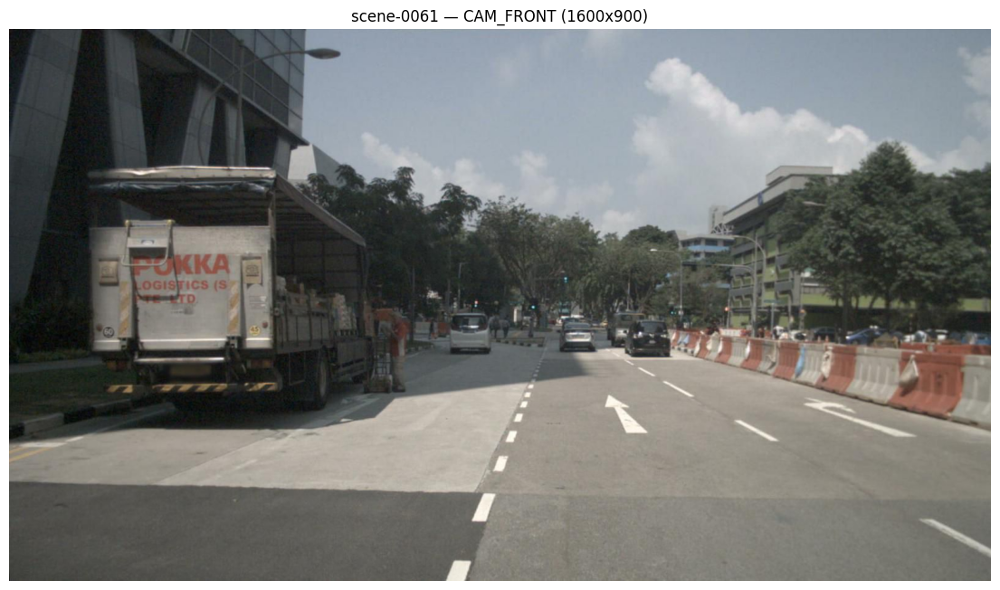

In [17]:
# Aperçu : première image CAM_FRONT de la scène 0 km
import matplotlib.pyplot as plt

by_token = lambda tab: {r['token']: r for r in tab}
samples, sensors = by_token(tables['sample']), by_token(tables['sensor'])
calibs,  poses   = by_token(tables['calibrated_sensor']), by_token(tables['ego_pose'])

cs_front = {cs['token'] for cs in tables['calibrated_sensor']
            if sensors[cs['sensor_token']]['channel'] == 'CAM_FRONT'}

scene0 = tables['scene'][0]
first  = next(sd for sd in tables['sample_data']
              if sd['sample_token'] == scene0['first_sample_token']
              and sd['is_key_frame'] and sd['calibrated_sensor_token'] in cs_front)

plt.figure(figsize=(14, 8))
plt.imshow(plt.imread(os.path.join(DATAROOT, first['filename'])))
plt.title(f"{scene0['name']} — CAM_FRONT ({first['width']}x{first['height']})")
plt.axis('off')
plt.show()

## 6. Export des poses caméra (`transforms.json`)

`transform_matrix` attend une matrice **caméra → monde**, d'où `T_ego_to_world @ T_cam_to_ego`.

Par défaut : `CAM_FRONT`, scène 0 → environ 40 images. C'est peu pour du 3DGS. Pour élargir,
passe une liste à `channels` (par exemple les 6 caméras) et/ou plusieurs `scene_indices`.

In [18]:
import shutil

def export_transforms(dataroot, output_dir, version='v1.0-mini',
                      channels=('CAM_FRONT',), scene_indices=(0,)):
    t = load_tables(dataroot, version)
    by = lambda tab: {r['token']: r for r in tab}
    samples, sensors = by(t['sample']), by(t['sensor'])
    calibs,  poses   = by(t['calibrated_sensor']), by(t['ego_pose'])

    wanted = {cs['token'] for cs in t['calibrated_sensor']
              if sensors[cs['sensor_token']]['channel'] in channels}

    # keyframes seulement (on écarte les sweeps intermédiaires)
    per_sample = {}
    for sd in t['sample_data']:
        if sd['is_key_frame'] and sd['calibrated_sensor_token'] in wanted:
            per_sample.setdefault(sd['sample_token'], []).append(sd)

    os.makedirs(f'{output_dir}/images', exist_ok=True)
    frames, ref = [], None

    for idx in scene_indices:
        token = t['scene'][idx]['first_sample_token']
        while token:
            for sd in per_sample.get(token, []):
                if ref is None:
                    ref = sd
                T = get_T(poses[sd['ego_pose_token']]) @ get_T(calibs[sd['calibrated_sensor_token']])
                dst = f"{sd['token']}.{sd['fileformat']}"
                shutil.copy(os.path.join(dataroot, sd['filename']), f'{output_dir}/images/{dst}')
                frames.append({'file_path': f'./images/{dst}',
                               'transform_matrix': T.tolist()})
            token = samples[token]['next']

    if not frames:
        raise RuntimeError('Aucune image trouvée — vérifie channels et scene_indices')

    K = calibs[ref['calibrated_sensor_token']]['camera_intrinsic']
    w, h = ref['width'], ref['height']
    data = {'camera_angle_x': float(2 * np.arctan(w / (2 * K[0][0]))),
            'fl_x': K[0][0], 'fl_y': K[1][1], 'cx': K[0][2], 'cy': K[1][2],
            'w': w, 'h': h, 'frames': frames}
    with open(f'{output_dir}/transforms.json', 'w') as f:
        json.dump(data, f, indent=4)
    return data

data = export_transforms(DATAROOT, OUTPUT_DIR, VERSION,
                         channels=('CAM_FRONT',), scene_indices=(0,))
print(f"{len(data['frames'])} images exportées → {OUTPUT_DIR}")
print(f"résolution {data['w']}x{data['h']} | FOV horizontal {np.degrees(data['camera_angle_x']):.1f}°")


39 images exportées → /kaggle/working/nerf_data
résolution 1600x900 | FOV horizontal 64.6°


In [19]:
# Contrôles de cohérence avant de lancer l'entraînement
n_img    = len(os.listdir(f'{OUTPUT_DIR}/images')) # nombre d'image"
n_frames = len(data['frames'])                     # nombre de frames dns transform.json
assert n_img == n_frames, f'{n_img} images vs {n_frames} frames' # si pas d'égalité alors il y a un problème

# Les rotations doivent être orthonormales (det = 1)
dets = [np.linalg.det(np.array(f['transform_matrix'])[:3, :3]) for f in data['frames']]
assert np.allclose(dets, 1.0), 'Matrices de rotation invalides' # regrde si le det des matrices de rotation valent bien 1

# distance totale parcourue par la caméra
pos  = np.array([np.array(f['transform_matrix'])[:3, 3] for f in data['frames']]) # on recupère les vecteurs translation de chaque frame donc pos est un tableau de forme (39, 3)
dist = np.linalg.norm(np.diff(pos, axis=0), axis=1).sum() # on fait la somme des déplacements

print(f'{n_img} images / {n_frames} frames')
print(f'det(R) ∈ [{min(dets):.6f}, {max(dets):.6f}]')
print(f'trajectoire parcourue : {dist:.1f} m')
print('\nCohérent ✅')


39 images / 39 frames
det(R) ∈ [1.000000, 1.000000]
trajectoire parcourue : 91.5 m

Cohérent ✅


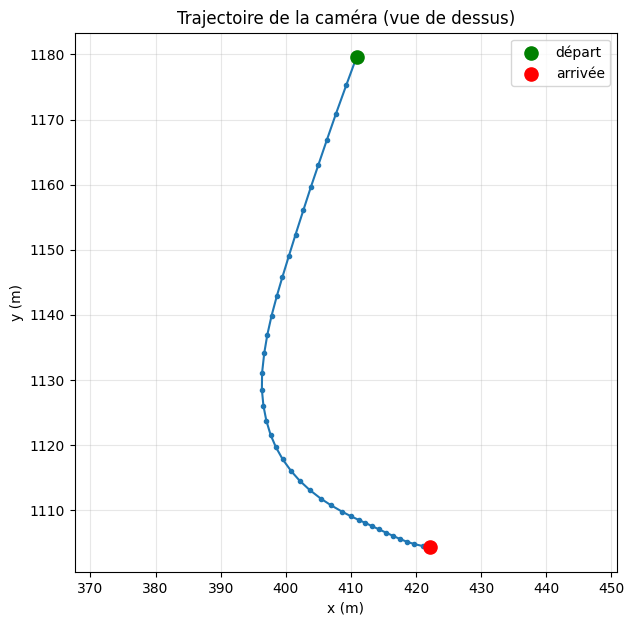

In [20]:
# Trajectoire vue du dessus — permet de repérer des poses aberrantes
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))
plt.plot(pos[:, 0], pos[:, 1], '-o', markersize=3)
plt.scatter(pos[0, 0], pos[0, 1], c='green', s=90, zorder=5, label='départ')
plt.scatter(pos[-1, 0], pos[-1, 1], c='red', s=90, zorder=5, label='arrivée')
plt.axis('equal'); plt.grid(alpha=.3); plt.legend()
plt.title('Trajectoire de la caméra (vue de dessus)')
plt.xlabel('x (m)'); plt.ylabel('y (m)')
plt.show()


## 7. Entraînement

7000 itérations au lieu des 30000 par défaut : suffisant sur ~40 images et bien plus économe en
quota GPU. À augmenter si le rendu est trop flou.

Les variables d'environnement sont repassées explicitement car `ns-train` est un sous-processus.

In [21]:
# passer de la convention openCV à openGL car on veut use Nerfstudio qui parle OpenGL ( une histoire d'axe de la caméra)
import os
OPENCV_TO_OPENGL = np.diag([1, -1, -1, 1])

with open(f'{OUTPUT_DIR}/transforms.json') as f:
    data = json.load(f)

for fr in data['frames']:
    fr['transform_matrix'] = (np.array(fr['transform_matrix']) @ OPENCV_TO_OPENGL).tolist()

with open(f'{OUTPUT_DIR}/transforms.json', 'w') as f:  # remplace le contenu de transform.json adapté mtn à OpenGL
    json.dump(data, f, indent=4)

In [22]:
# # training

# os.environ['MAX_JOBS'] = '2'
# os.environ['TORCH_EXTENSIONS_DIR'] = '/kaggle/working/torch_extensions'

# cmd = (
#     'ns-train splatfacto'
#     f' --data {OUTPUT_DIR}'
#     ' --output-dir /kaggle/working/outputs'
#     ' --max-num-iterations 7000'
#     ' --viewer.quit-on-train-completion True'
#     ' --pipeline.model.num-downscales 2'
#     ' nerfstudio-data'
# )
# print(cmd)

# !{cmd}


In [23]:
# Un .ckpt présent = entraînement allé au bout
!find /kaggle/working/outputs -name '*.ckpt' 2>/dev/null | sort


/kaggle/working/outputs/exp6_L3/splatfacto/2026-10-21_104521/nerfstudio_models/step-000017999.ckpt
/kaggle/working/outputs/exp7_3cams/splatfacto/2026-10-21_160447/nerfstudio_models/step-000002500.ckpt
/kaggle/working/outputs/exp7_3cams/splatfacto/2026-10-21_160447/nerfstudio_models/step-000005000.ckpt
/kaggle/working/outputs/exp7_3cams/splatfacto/2026-10-21_160447/nerfstudio_models/step-000007500.ckpt
/kaggle/working/outputs/exp7_3cams/splatfacto/2026-10-21_160447/nerfstudio_models/step-000010000.ckpt
/kaggle/working/outputs/exp7_3cams/splatfacto/2026-10-21_160447/nerfstudio_models/step-000012500.ckpt
/kaggle/working/outputs/exp7_3cams/splatfacto/2026-10-21_160447/nerfstudio_models/step-000015000.ckpt
/kaggle/working/outputs/exp7_3cams/splatfacto/2026-10-21_160447/nerfstudio_models/step-000017500.ckpt
/kaggle/working/outputs/exp7_3cams/splatfacto/2026-10-21_160447/nerfstudio_models/step-000017999.ckpt
/kaggle/working/outputs/nerf_data_A_prime/splatfacto/2026-10-14_105020/nerfstudio_mod

### Export du nuage de gaussiennes

In [24]:
# plomberie
import glob

configs = sorted(glob.glob('/kaggle/working/outputs/**/config.yml', recursive=True))
print('\n'.join(configs) if configs else 'Aucun config.yml — entraînement non terminé')


/kaggle/working/outputs/exp6_L3/splatfacto/2026-10-21_104521/config.yml
/kaggle/working/outputs/exp7_3cams/splatfacto/2026-10-21_160447/config.yml
/kaggle/working/outputs/nerf_data/splatfacto/2026-09-25_213207/config.yml
/kaggle/working/outputs/nerf_data_A_prime/splatfacto/2026-10-14_105020/config.yml
/kaggle/working/outputs/nerf_data_B/splatfacto/2026-10-14_110945/config.yml
/kaggle/working/outputs/nerf_data_B_30k/splatfacto/2026-10-16_115053/config.yml
/kaggle/working/outputs/nerf_data_tvt/splatfacto/2026-10-20_202148/config.yml
/kaggle/working/outputs/nerf_data_tvt_lidar/splatfacto/2026-10-20_220400/config.yml


In [25]:
# # Exporte la scène entraînée en .ply pour l'ouvrir dans un visualiseur 3D.
# # TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD : nerfstudio 1.1.5 date d'avant PyTorch 2.6,
# # dont torch.load refuse par défaut de relire nos checkpoints (fichier de confiance : le nôtre).
# if configs:
#     cfg = configs[-1]
#     !TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1 ns-export gaussian-splat --load-config {cfg} --output-dir /kaggle/working/exports
#     !ls -lh /kaggle/working/exports

In [26]:
# Nuage 3D interactif : centres des gaussiennes avec leur couleur
import numpy as np, plotly.graph_objects as go
from plyfile import PlyData

v = PlyData.read('/kaggle/working/exports/splat.ply')['vertex']
xyz = np.stack([v['x'], v['y'], v['z']], axis=1)
rgb = np.clip(0.5 + 0.28209479 * np.stack([v['f_dc_0'], v['f_dc_1'], v['f_dc_2']], axis=1), 0, 1)
opa = 1 / (1 + np.exp(-v['opacity']))

# On garde les gaussiennes bien opaques, sans les points aberrants très lointains
keep = opa > 0.5
lo, hi = np.percentile(xyz[keep], [2, 98], axis=0)
keep &= np.all((xyz >= lo) & (xyz <= hi), axis=1)

# 60 000 points tirés au hasard, pour que l'affichage reste fluide
idx = np.random.default_rng(0).choice(np.flatnonzero(keep), size=min(60000, keep.sum()), replace=False)
couleurs = [f'rgb({r},{g},{b})' for r, g, b in (rgb[idx] * 255).astype(int)]

fig = go.Figure(go.Scatter3d(x=xyz[idx, 0], y=xyz[idx, 1], z=xyz[idx, 2],
                             mode='markers', marker=dict(size=1.5, color=couleurs)))
fig.update_layout(scene=dict(aspectmode='data'), height=700, margin=dict(l=0, r=0, t=0, b=0))
from IPython.display import HTML
HTML(fig.to_html(include_plotlyjs='cdn'))

Ce qu'on voit là, ce sont les centres des gaussiennes après entrainement ainsi que leurs couleurs. Il est vrai qu'un point n'a pas de couleur car pas de dimension mais pour un rendu visuel les points sont gros et colorés avec la couleur de leur gaussienne.

In [27]:
# # Filme la scène 3D le long du trajet de la caméra avant (vidéo .mp4)
# # génère un rendu vidéo MP4 en interpolant les poses d'entraînement via ns-render interpolate, puis vérifie la taille du fichier créé.
# import glob
# cfg = sorted(glob.glob('/kaggle/working/outputs/nerf_data/splatfacto/2026-09-25_213207/config.yml', recursive = True))[-1]
# !TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1 ns-render interpolate --load-config {cfg} --pose-source train --output-path /kaggle/working/renders/trajectoire.mp4
# !ls -lh /kaggle/working/renders

In [28]:
# Affiche la vidéo rendue directement dans le notebook
from IPython.display import Video
Video('/kaggle/working/renders/trajectoire.mp4', embed=True, width=900)

# Analyse

Le rendu est réaliste le long du trajet, mais il est mauvais dès qu’on s’en écarte (aiguilles, gaussiennes flottantes).
Causes probables :
seulement environ 35 images, toutes tournées vers l’avant, avec très peu de décalage latéral : la profondeur est mal contrainte ;
initialisation aléatoire des gaussiennes ;
objets mobiles (voitures, piétons) qui contredisent l’hypothèse d’une scène statique.
Le rendu sur le trajet mesure la fidélité aux images d’entraînement, pas la généralisation.

**Aiguille** : c'est une gaussienne très étirée dans une direction. 

# Conclusion

La reconstruction fonctionne près du trajet de la caméra, et les poses sont validées. En revanche, on ne peut rien conclure sur la synthèse de nouvelles vues, faute de mesure chiffrée.

# Questions

Plus d’images (les sweeps) améliorent-elles la qualité sur des vues jamais vues ? C’est l’expérience 3.
Jusqu’à quel décalage latéral (1 m, 2 m, 3 m ?) le rendu reste-t-il crédible ?
Une initialisation par le lidar réduit-elle les aiguilles ?

Je rappelle que les is_key_frames sont au nombre de 40 en moyenne par scène.
Voici le rendu de la scène en ne considérant que les is_key_frames donc pas les sweeps.

In [29]:
# Vidéo des 39 vraies photos CAM_FRONT de scene-0061, pour comparer avec le rendu
import json, os, numpy as np, mediapy as media
from PIL import Image
from IPython.display import Video

tj = json.load(open('/kaggle/working/nerf_data/transforms.json'))
images = [np.array(Image.open(os.path.join('/kaggle/working/nerf_data', f['file_path'])).resize((800, 450)))
          for f in tj['frames']]

os.makedirs('/kaggle/working/renders', exist_ok=True)
media.write_video('/kaggle/working/renders/originale.mp4', images, fps=4)
Video('/kaggle/working/renders/originale.mp4', embed=True, width=900)

Voici la même scène avec les sweeps en plus. Il est bien évidemment attendu une meilleure fluidité. Une scène plus réaliste avec la même vitesse de perception qu'un humain.

In [30]:
# Vidéo de TOUTES les images CAM_FRONT de scene-0061 (keyframes + sweeps), en temps réel
import json, os, numpy as np, mediapy as media
from PIL import Image
from IPython.display import Video

root = '/kaggle/working/data/sets/nuscenes'
load = lambda n: json.load(open(f'{root}/v1.0-mini/{n}.json'))
sensors = {s['token']: s for s in load('sensor')}
calibs  = {c['token']: c for c in load('calibrated_sensor')}
sds     = {sd['token']: sd for sd in load('sample_data')}
scene0  = load('scene')[0]

# première image CAM_FRONT de la scène, puis on suit la chaîne 'next'
sd = next(s for s in sds.values()
          if s['sample_token'] == scene0['first_sample_token']
          and sensors[calibs[s['calibrated_sensor_token']]['sensor_token']]['channel'] == 'CAM_FRONT')
images = []
while sd:
    images.append(np.array(Image.open(f"{root}/{sd['filename']}").resize((800, 450))))
    sd = sds.get(sd['next'])

print(len(images), 'images')
media.write_video('/kaggle/working/renders/originale_complete.mp4', images, fps=12)
Video('/kaggle/working/renders/originale_complete.mp4', embed=True, width=900)

224 images


---
**Suite :** partie 2, expérience 3 (A' contre B) et recherche du nombre d'itérations optimal.
